# PBMC cell-type classification: within-dataset vs a new donor

Walkthrough of the `scpbmc` package. We train classifiers on **PBMC 3k** (10x Genomics) and
check them two ways:

1. 5-fold stratified cross-validation inside PBMC 3k (the usual, optimistic way)
2. training on PBMC 3k and testing on **PBMC 68k reduced**, a different donor whose labels come
   from a different method (correlation with FACS-sorted bulk profiles)

In [1]:
import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from scpbmc.data import load_pbmc3k, load_pbmc68k_reduced, to_coarse, COARSE_3K, COARSE_68K
from scpbmc.preprocess import log_normalize
adata, fine = load_pbmc3k("../data/raw")
print(adata)
pd.Series(fine).value_counts()

AnnData object with n_obs × n_vars = 2638 × 32738
    var: 'gene_ids'


CD4 T cells          1144
CD14+ Monocytes       480
B cells               342
CD8 T cells           316
NK cells              154
FCGR3A+ Monocytes     150
Dendritic cells        37
Megakaryocytes         15
Name: count, dtype: int64

## 1. What does the raw data look like?
UMI counts are sparse: most genes are 0 in most cells.

In [2]:
X = adata.X
print("fraction of zeros:", round(1 - X.nnz / (X.shape[0] * X.shape[1]), 4))
totals = np.asarray(X.sum(1)).ravel()
print("UMIs per cell: median", int(np.median(totals)), "min", int(totals.min()), "max", int(totals.max()))

fraction of zeros: 0.974
UMIs per cell: median 2214 min 561 max 8931


## 2. Library-size normalisation + log1p (by hand)

In [3]:
x = log_normalize(X[:5])
print(np.expm1(x).sum(1))  # every cell now sums to 10,000 before the log

[10000.003 10000.049 10000.067 10000.055 10000.002]


## 3. Results from the full experiment (`python -m scpbmc.evaluate`)

In [4]:
m = json.load(open("../results/metrics.json"))
rows = []
for block in ["cv_fine", "cv_coarse"]:
    for model, s in m[block].items():
        rows.append([block, model, s["macro_f1"]["mean"], s["macro_f1"]["std"], s["accuracy"]["mean"]])
pd.DataFrame(rows, columns=["setting", "model", "macroF1", "sd", "accuracy"]).round(3)

,setting,model,macroF1,sd,accuracy
0,cv_fine,logreg,0.878,0.026,0.937
1,cv_fine,knn_pca,0.871,0.022,0.923
2,cv_fine,random_forest,0.895,0.026,0.940
3,cv_coarse,logreg,0.888,0.029,0.947
4,cv_coarse,knn_pca,0.872,0.029,0.930
5,cv_coarse,random_forest,0.902,0.046,0.950
6,cv_coarse,marker_baseline,0.633,0.018,0.761


In [5]:
c = m["cross"]
pd.DataFrame({k: v for k, v in c.items() if isinstance(v, dict) and "macro_f1" in v}).T.round(3)

,accuracy,balanced_accuracy,macro_f1
logreg|none,0.798,0.798,0.786
knn_pca|none,0.789,0.779,0.763
random_forest|none,0.812,0.814,0.807
logreg|per_dataset_zscore,0.518,0.625,0.546
knn_pca|per_dataset_zscore,0.502,0.619,0.538
random_forest|per_dataset_zscore,0.595,0.678,0.627
marker_baseline,0.734,0.783,0.704


## 4. Why did per-dataset z-scoring make things worse?

Z-scoring each dataset separately subtracts that dataset's mean expression. That only works if both
datasets contain the **same mix of cell types**. They don't:

In [6]:
y68 = to_coarse(load_pbmc68k_reduced()[1], COARSE_68K)
y3k = to_coarse(fine, COARSE_3K)
comp = pd.DataFrame({
    "PBMC3k %": pd.Series(y3k).value_counts(normalize=True) * 100,
    "PBMC68k-reduced %": pd.Series([v for v in y68 if v]).value_counts(normalize=True) * 100,
}).round(1)
comp

,PBMC3k %,PBMC68k-reduced %
B,13.0,13.8
CD4 T,43.4,13.8
CD8 T,12.0,14.1
Dendritic,1.4,34.9
Megakaryocyte,0.6,NaN
Monocyte,23.9,18.8
NK,5.8,4.5


## 5. Figures

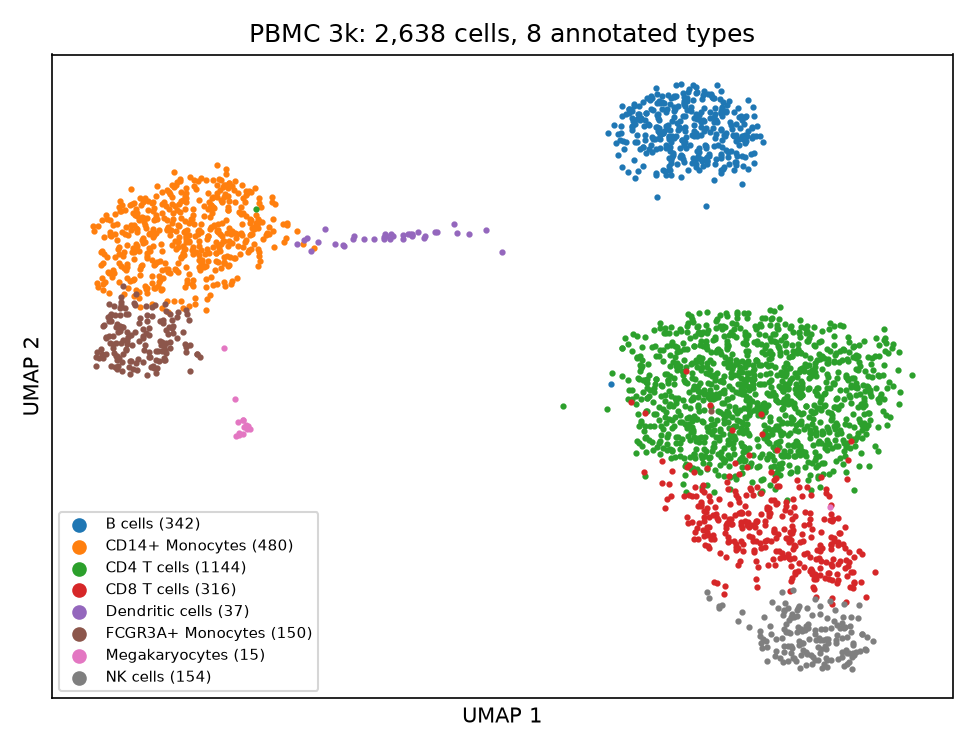

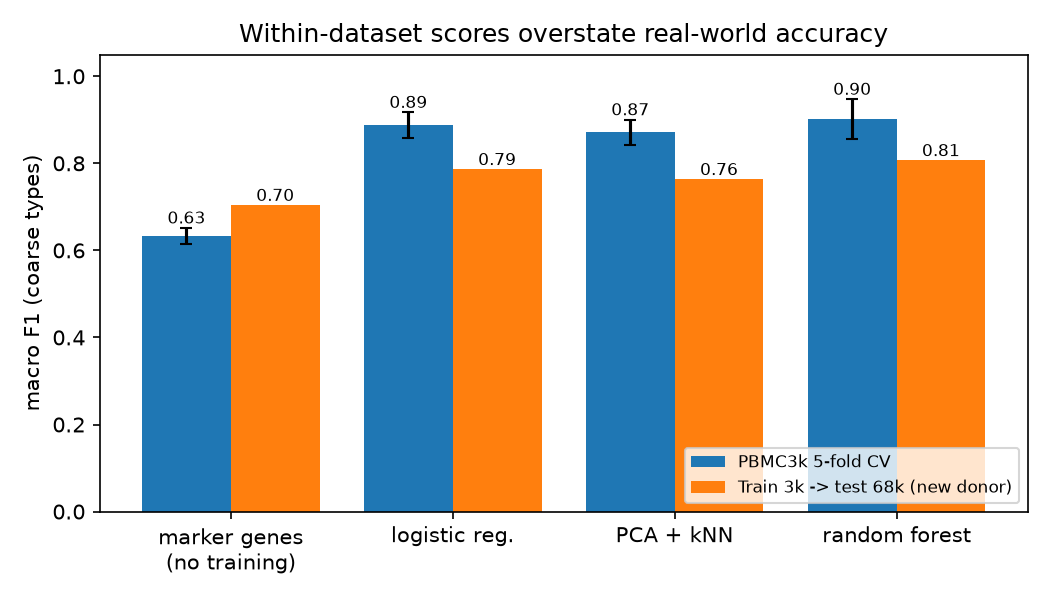

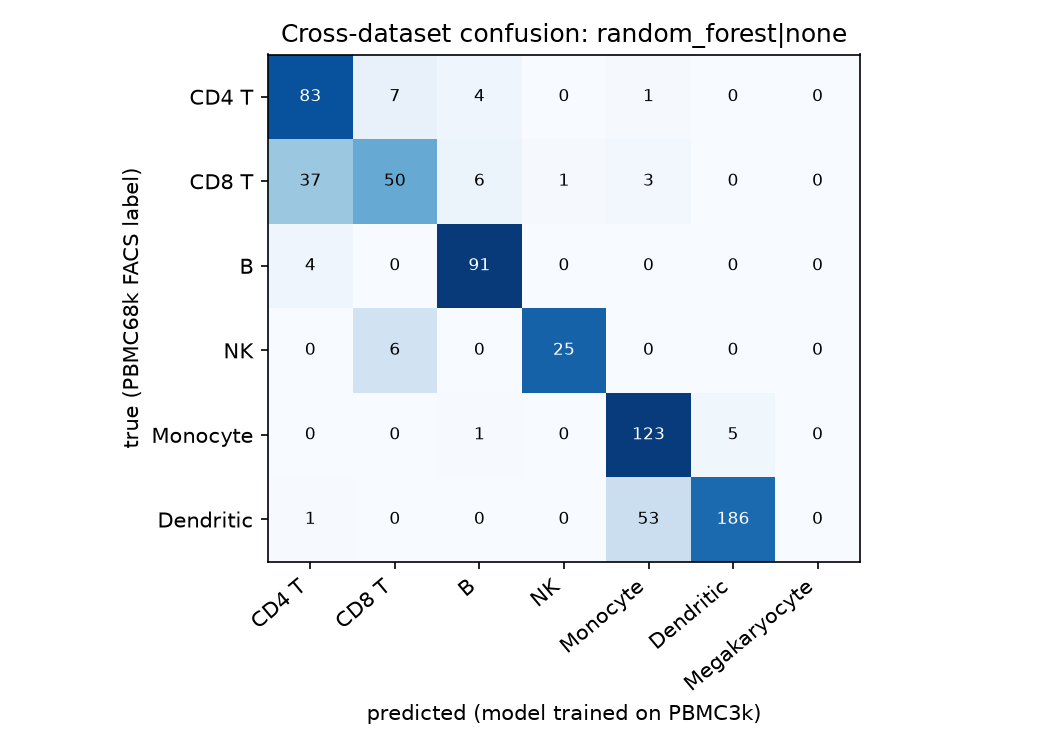

In [7]:
from IPython.display import Image, display
for f in ["umap_pbmc3k", "within_vs_cross", "cross_confusion"]:
    display(Image(f"../results/figures/{f}.png"))